# Laboratorio de Simulación Computacional, Práctica N.° 05
## estadística descriptiva y análisis de datos de entrada (secciones 5.1 y 5.2)

Luciana Alejandra Belandria Agudelo (160005005)

Universidad de los Llanos, Ingeniería de Sistemas


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.simplefilter("ignore")
pd.options.display.float_format = "{:,.6g}".format

ETIQUETAS = ["A", "B", "C", "D"]
PARTICIONES = 20
MAX_RETRASO = 20
ANCHO_VENTANA = 20
CARPETA_FIG = Path("graficas")
CARPETA_FIG.mkdir(exist_ok=True)

In [2]:
pendientes = [f"dataset-{e}.txt" for e in ETIQUETAS if not Path(f"dataset-{e}.txt").exists()]
if pendientes:
    from google.colab import files
    print("Faltan:", pendientes)
    files.upload()

muestras = {e: np.loadtxt(f"dataset-{e}.txt") for e in ETIQUETAS}

def exportar(fig, nombre):
    fig.savefig(CARPETA_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

print({e: v.size for e, v in muestras.items()})

Faltan: ['dataset-A.txt', 'dataset-B.txt', 'dataset-C.txt', 'dataset-D.txt']


Saving dataset-A.txt to dataset-A.txt
Saving dataset-B.txt to dataset-B.txt
Saving dataset-C.txt to dataset-C.txt
Saving dataset-D.txt to dataset-D.txt
{'A': 200, 'B': 200, 'C': 200, 'D': 200}


## Parte 1. Descripción estadística de las muestras (guía, sección 5.1)

In [3]:
def resumen_numerico(x):
    n = x.size
    media = x.sum() / n
    desv = x - media
    s2 = (desv ** 2).sum() / (n - 1)
    s = np.sqrt(s2)
    m2 = (desv ** 2).mean()
    g1 = (desv ** 3).mean() / m2 ** 1.5
    g2 = (desv ** 4).mean() / m2 ** 2 - 3
    asimetria = g1 * np.sqrt(n * (n - 1)) / (n - 2)
    curtosis = (n - 1) / ((n - 2) * (n - 3)) * ((n + 1) * g2 + 6)
    q1, q2, q3 = np.quantile(x, [0.25, 0.50, 0.75])
    return pd.Series({
        "Tamaño de la muestra": n,
        "Mínimo": x.min(),
        "Máximo": x.max(),
        "Media": media,
        "Varianza": s2,
        "Desviación estándar": s,
        "Percentil 25% (Q1)": q1,
        "Percentil 50% (Q2 o mediana)": q2,
        "Percentil 75% (Q3)": q3,
        "Asimetría": asimetria,
        "Curtosis (exceso)": curtosis,
        "Coeficiente de variación": s / media,
    })

descriptiva = pd.concat({f"Dataset {e}": resumen_numerico(v) for e, v in muestras.items()}, axis=1)
display(descriptiva)

,Dataset A,Dataset B,Dataset C,Dataset D
Tamaño de la muestra,200,200,200,200
Mínimo,0.0209639,8.516e-05,0.926681,0.111505
Máximo,0.298966,1.55131,"6,669.85",17.967
Media,0.195039,0.205393,762.394,2.0605
Varianza,0.00191929,0.0524807,"852,170",5.41299
Desviación estándar,0.0438098,0.229087,923.13,2.32658
Percentil 25% (Q1),0.163843,0.0463288,152.912,0.634291
Percentil 50% (Q2 o mediana),0.192074,0.137676,455.558,1.40636
Percentil 75% (Q3),0.230109,0.290179,"1,028.59",2.52891
Asimetría,-0.291711,2.42459,2.50089,3.18352


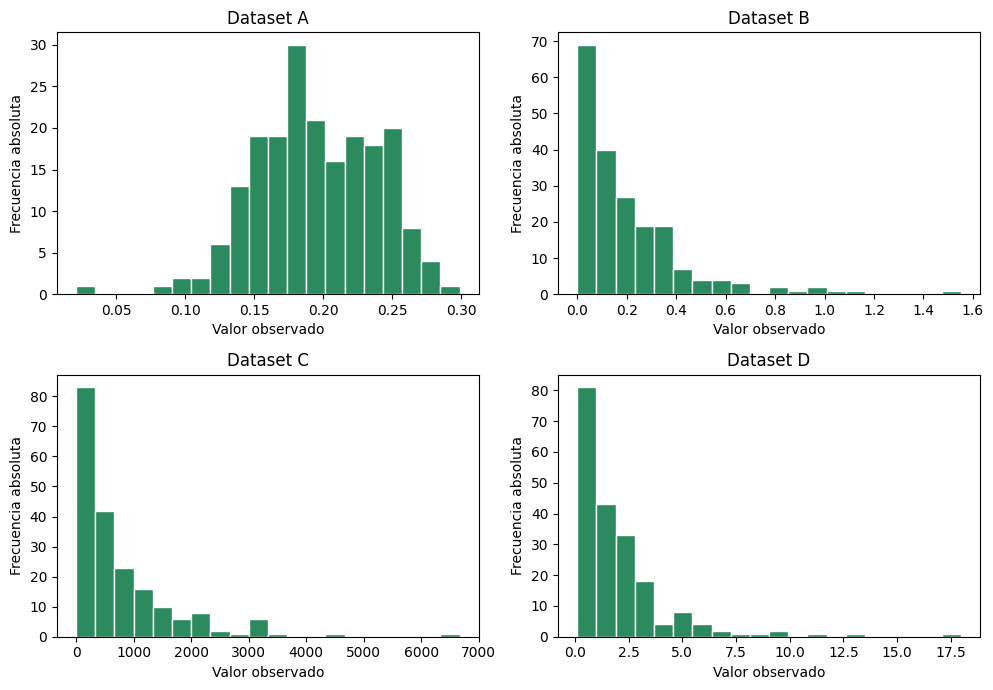

In [4]:
lienzo, celdas = plt.subplots(2, 2, figsize=(10, 7))
for celda, e in zip(celdas.flat, ETIQUETAS):
    celda.hist(muestras[e], bins=PARTICIONES, color="#2b8a5e", edgecolor="white")
    celda.set(title=f"Dataset {e}", xlabel="Valor observado", ylabel="Frecuencia absoluta")
lienzo.tight_layout()
exportar(lienzo, "hist_cuatro_muestras")
plt.show()

## Parte 2. Supuestos de independencia y estabilidad (guía, sección 5.2)

Cada dato se interpreta como el tiempo transcurrido entre dos llegadas consecutivas. Las llegadas ocurren en los instantes acumulados y el horizonte observado es la suma de todos los datos.

In [5]:
def autocorrelaciones(x, retrasos):
    centrada = x - x.mean()
    return np.array([np.corrcoef(centrada[:-k], centrada[k:])[0, 1] for k in range(1, retrasos + 1)])

def instantes(x):
    return np.cumsum(x)

def conteo_por_tramo(x, tramos):
    llegadas = instantes(x)
    limites = np.linspace(0, llegadas[-1], tramos + 1)
    conteo, _ = np.histogram(llegadas, bins=limites)
    return conteo

def promedio_movil(x, ventana):
    medio = round(ventana / 2)
    salida = []
    for j in range(1, x.size):
        a = j - min(medio, j)
        b = j + min(medio, x.size - j)
        salida.append(x[a:b].mean())
    return np.array(salida)

def tablero_supuestos(e):
    x = muestras[e]
    rho = autocorrelaciones(x, MAX_RETRASO)
    limite = 1.96 / np.sqrt(x.size)
    llegadas = instantes(x)
    mm = promedio_movil(x, ANCHO_VENTANA)

    lienzo, ejes = plt.subplots(2, 3, figsize=(14, 7.5))
    ejes = ejes.flat

    ejes[0].plot(np.arange(x.size), x, ".", color="#8e44ad", ms=4)
    ejes[0].set(title="Secuencia de datos", xlabel="Posición i", ylabel="$x_i$")

    ejes[1].axhspan(-limite, limite, color="#d6eaf8")
    ejes[1].vlines(range(1, MAX_RETRASO + 1), 0, rho, color="#1f618d")
    ejes[1].plot(range(1, MAX_RETRASO + 1), rho, "o", color="#1f618d")
    ejes[1].axhline(0, color="black", lw=0.8)
    ejes[1].set(title="(a) Correlación de retraso", xlabel="Retraso k", ylabel="$\\hat{\\rho}_k$", ylim=(-1, 1))

    ejes[2].plot(x[:-1], x[1:], "^", color="#1f618d", ms=4)
    ejes[2].set(title="(b) Diagrama de dispersión", xlabel="$x_k$", ylabel="$x_{k+1}$")
    ejes[2].grid(alpha=0.4)

    ejes[3].plot(llegadas, np.arange(1, x.size + 1) / x.size, color="#1f618d")
    ejes[3].plot([0, llegadas[-1]], [0, 1], "--", color="gray")
    ejes[3].ticklabel_format(axis="x", style="sci", scilimits=(-3, 4))
    ejes[3].set(title="(c) Patrón de tiempos de llegada", xlabel="Tiempo", ylabel="Fracción de llegadas")

    ejes[4].bar(range(1, PARTICIONES + 1), conteo_por_tramo(x, PARTICIONES), width=1, color="white", edgecolor="black")
    ejes[4].set(title="(d) Llegadas por intervalo", xlabel="Intervalo", ylabel="Cantidad")

    centro, dispersion = mm.mean(), mm.std()
    ejes[5].plot(mm, color="#1f618d")
    for nivel, color in [(centro, "black"), (centro + 3 * dispersion, "#c0392b"), (centro - 3 * dispersion, "#c0392b")]:
        ejes[5].axhline(nivel, color=color)
    ejes[5].set(title=f"(e) Media móvil, ventana {ANCHO_VENTANA}", xlabel="Posición", ylabel="Promedio local", xlim=(0, mm.size))

    lienzo.suptitle(f"Evaluación de supuestos, Dataset {e}", fontsize=14)
    lienzo.tight_layout()
    exportar(lienzo, f"supuestos_{e}")
    plt.show()

    mitad = x.size // 2
    return {"rho_1": rho[0],
            "Retrasos fuera de banda": [k for k, r in enumerate(rho, start=1) if abs(r) > limite],
            "Media 1.a mitad": x[:mitad].mean(),
            "Media 2.a mitad": x[mitad:].mean()}

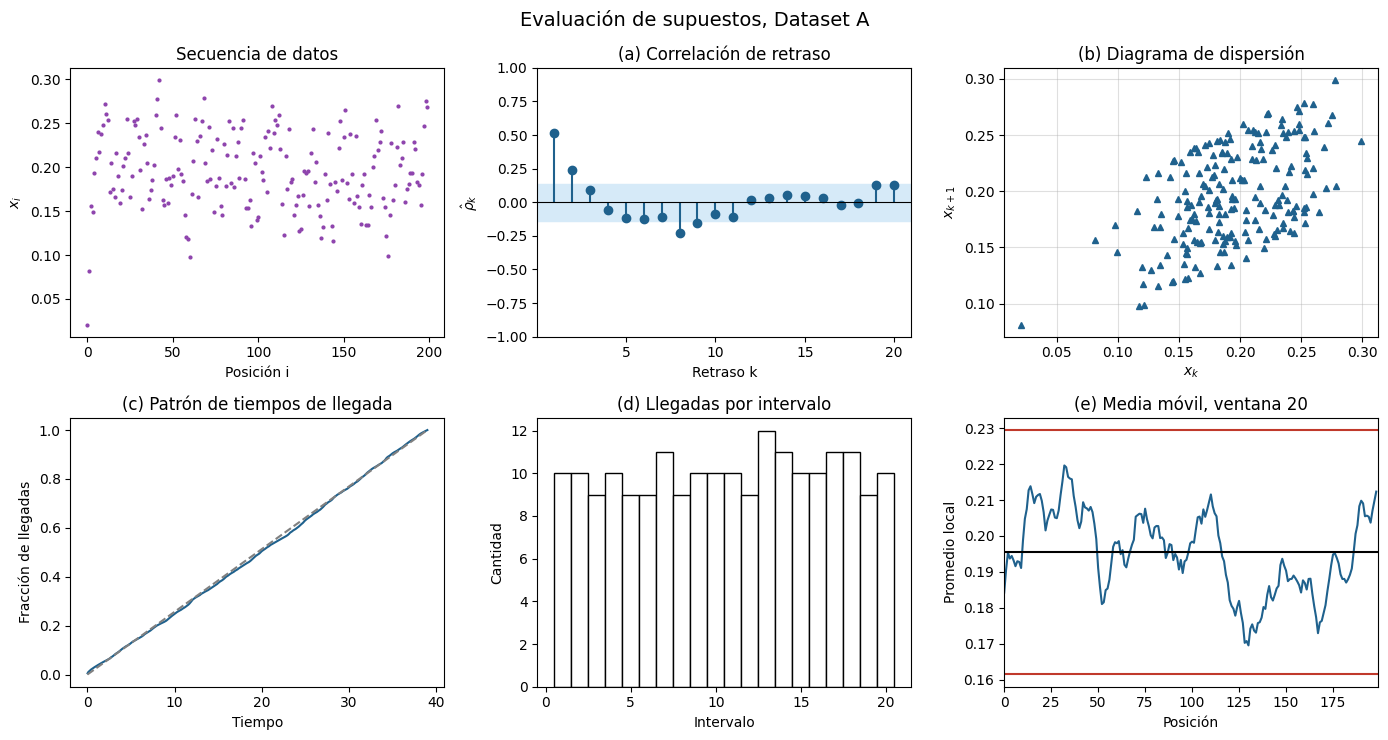

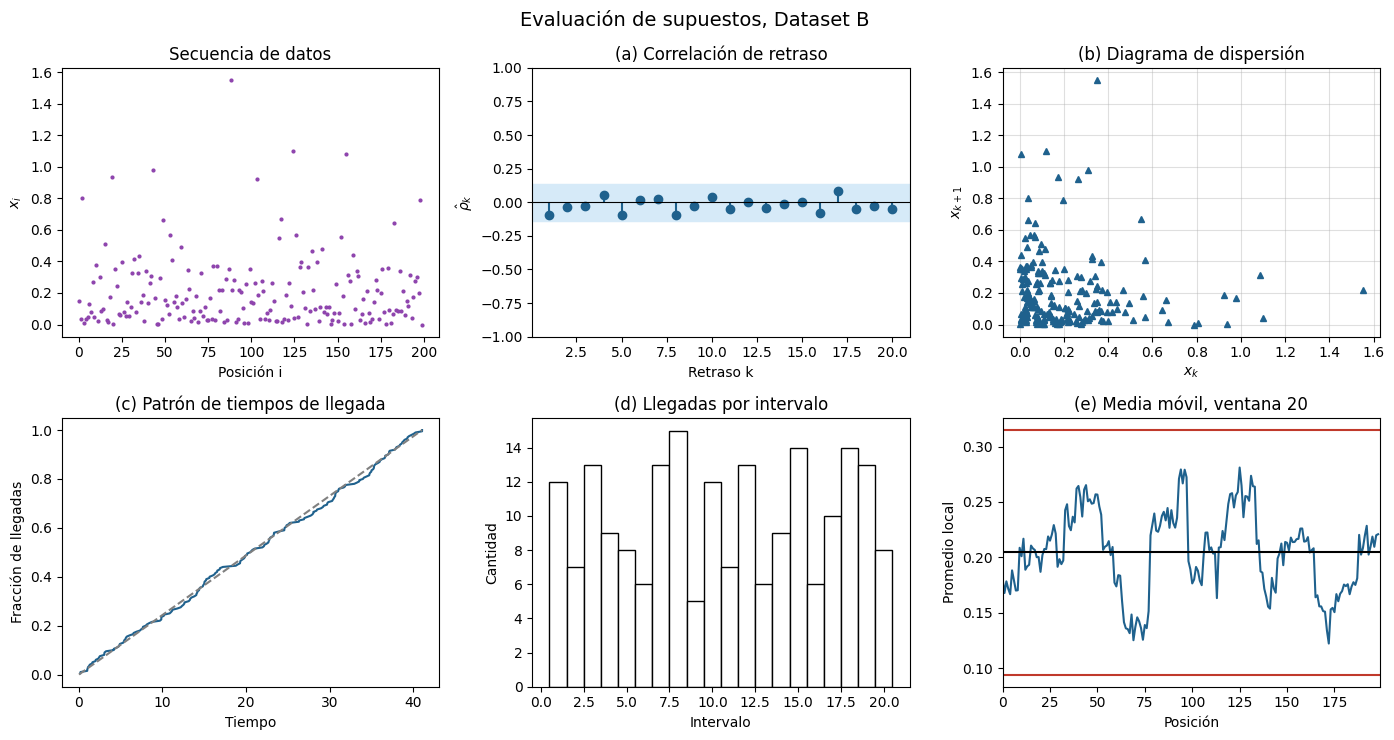

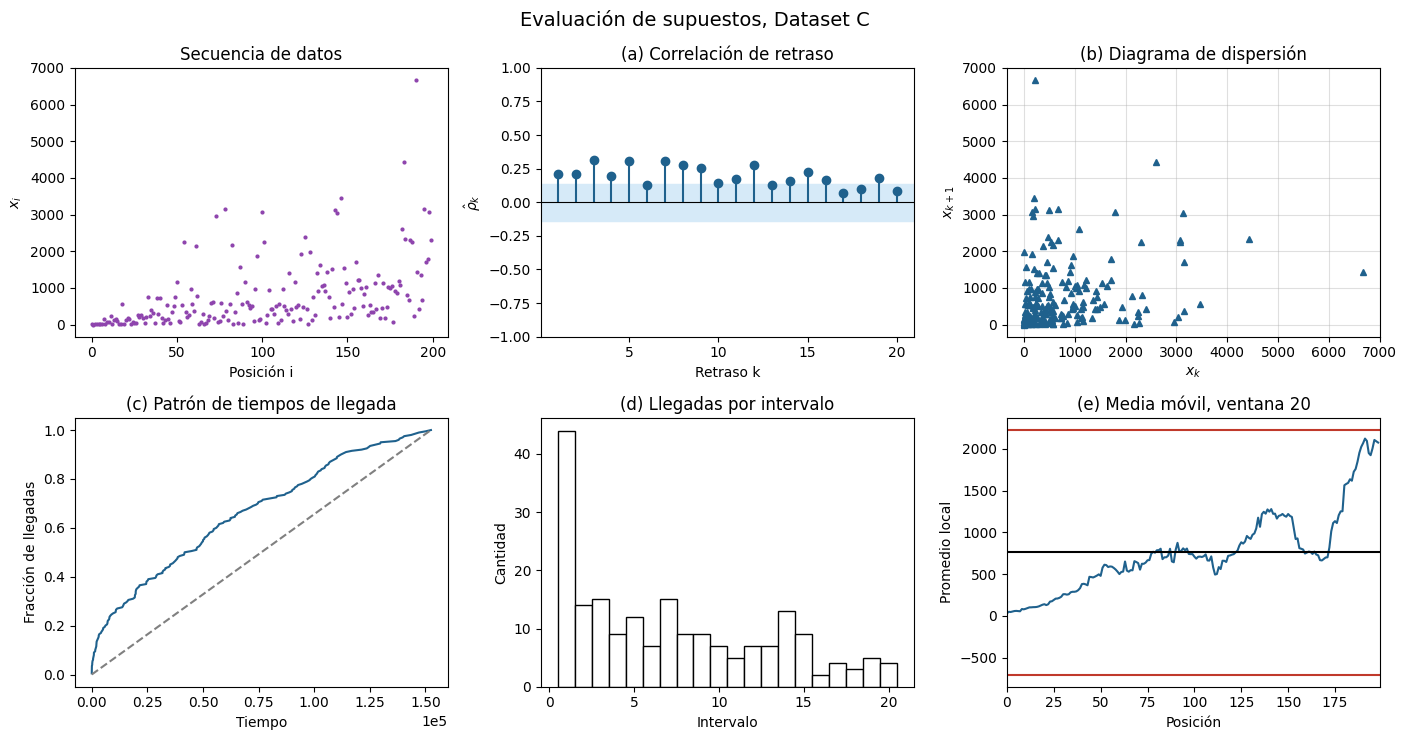

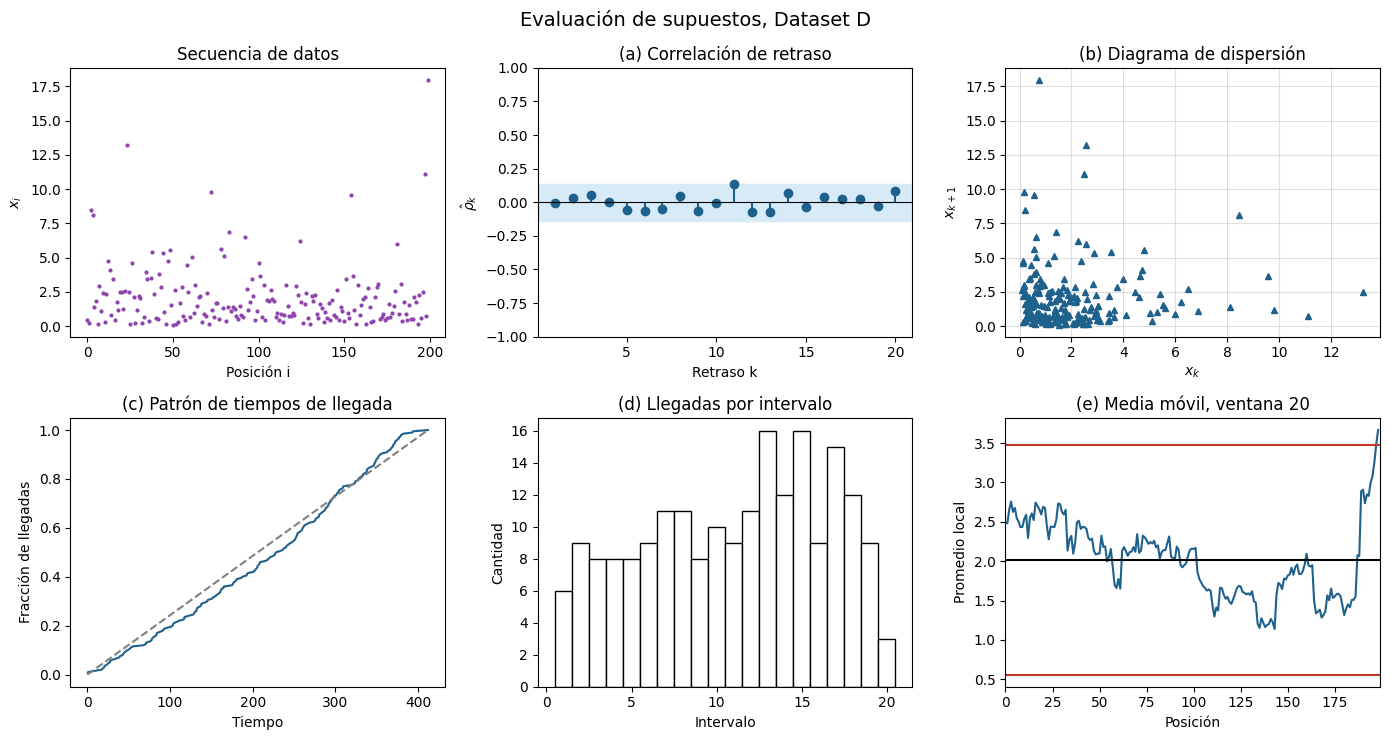

,rho_1,Retrasos fuera de banda,Media 1.a mitad,Media 2.a mitad
A,0.516879,"[1, 2, 8, 9]",0.19876,0.191317
B,-0.0925453,[],0.204951,0.205836
C,0.210232,"[1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 14, 15, 1...",417.558,"1,107.23"
D,-0.00259217,[],2.28299,1.83801


In [6]:
indicadores = pd.DataFrame({e: tablero_supuestos(e) for e in ETIQUETAS}).T
display(indicadores)

### Vista conjunta

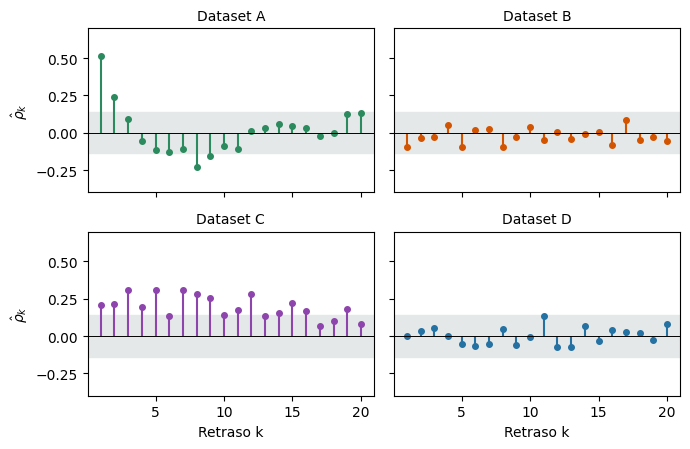

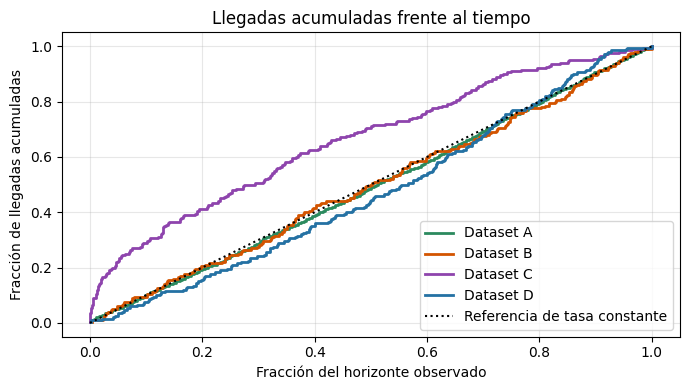

In [7]:
tonos = dict(zip(ETIQUETAS, ["#2b8a5e", "#d35400", "#8e44ad", "#2471a3"]))
limite = 1.96 / np.sqrt(200)

lienzo, ejes = plt.subplots(2, 2, figsize=(7, 4.6), sharex=True, sharey=True)
for eje, e in zip(ejes.flat, ETIQUETAS):
    rho = autocorrelaciones(muestras[e], MAX_RETRASO)
    eje.axhspan(-limite, limite, color="#e5e8e8")
    eje.vlines(range(1, MAX_RETRASO + 1), 0, rho, color=tonos[e])
    eje.plot(range(1, MAX_RETRASO + 1), rho, "o", color=tonos[e], ms=4)
    eje.axhline(0, color="black", lw=0.7)
    eje.set_title(f"Dataset {e}", fontsize=10)
    eje.set_ylim(-0.4, 0.7)
for eje in ejes[1]:
    eje.set_xlabel("Retraso k")
for eje in ejes[:, 0]:
    eje.set_ylabel("$\\hat{\\rho}_k$")
lienzo.tight_layout()
exportar(lienzo, "acf_conjunta")
plt.show()

lienzo, eje = plt.subplots(figsize=(7, 4))
for e in ETIQUETAS:
    t = instantes(muestras[e])
    eje.step(t / t[-1], np.arange(1, t.size + 1) / t.size, where="post", color=tonos[e], lw=2, label=f"Dataset {e}")
eje.plot([0, 1], [0, 1], ":", color="black", label="Referencia de tasa constante")
eje.set(xlabel="Fracción del horizonte observado", ylabel="Fracción de llegadas acumuladas",
        title="Llegadas acumuladas frente al tiempo")
eje.legend()
eje.grid(alpha=0.3)
lienzo.tight_layout()
exportar(lienzo, "llegadas_conjunta")
plt.show()